# 01. Spanish market structural breakdown
The objetive of this notebook is to provide a general understanding of the spanish continuous market, in order to do so we will analize:
- General market structure by sector and companies
- Large vs Mid cap
- Macroeconmic exposure
- Structural behaviour

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
import time

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (14, 7)

# 1. Cargar Datos Históricos de Precio (Descargados con download_data.py)
print("Cargando 15 años de datos offline...")
prices = pd.read_csv("../data/raw/stocks_close_15y.csv", index_col=0, parse_dates=True)
adj_prices = pd.read_csv("../data/raw/stocks_adjclose_15y.csv", index_col=0, parse_dates=True)
volumes = pd.read_csv("../data/raw/stocks_volume_15y.csv", index_col=0, parse_dates=True)
macro = pd.read_csv("../data/raw/macro_close_15y.csv", index_col=0, parse_dates=True)

returns = prices.pct_change().dropna(how='all')
adj_returns = adj_prices.pct_change().dropna(how='all')

# 2. Definir Universos (Excluimos activos muertos/tóxicos como DIA)
ibex35_tickers = [c for c in prices.columns if c in ["ANA.MC", "ANE.MC", "ACS.MC", "AENA.MC", "AMS.MC", "MTS.MC", "SAB.MC", "SAN.MC", "BKT.MC", "BBVA.MC", "CABK.MC", "CLNX.MC", "ENG.MC", "ELE.MC", "FER.MC", "FDR.MC", "GRF.MC", "IAG.MC", "IBE.MC", "ITX.MC", "LOG.MC", "MAP.MC", "MEL.MC", "MRL.MC", "NTGY.MC", "RED.MC", "REP.MC", "ROVI.MC", "SCYR.MC", "SLR.MC", "TEF.MC", "UNI.MC", "VIS.MC", "COL.MC", "PUIG.MC"]]
midcap_tickers = [c for c in prices.columns if c not in ibex35_tickers]
all_tickers = ibex35_tickers + midcap_tickers

Cargando 15 años de datos offline...


# MODULE 1: MARKET PHOTOGRAPHY

In [74]:
# Descargar Metadata (Sector y Market Cap)
print(f"Descargando Metadata para {len(all_tickers)} tickers...")
metadata = []

# Fetch data
for ticker in all_tickers:
    try:
        stock = yf.Ticker(ticker)
        info = stock.info
        if 'shortName' in info:
            metadata.append({
                "Ticker": ticker,
                "Name": info.get("shortName", ticker),
                "Sector": info.get("sector", "Unknown"),
                "MarketCap": info.get("marketCap", 0),
                "Is_IBEX35": ticker in ibex35_tickers
            })
    except Exception as e:
        print(f"Error con {ticker}: {e}")

df_market = pd.DataFrame(metadata)
df_market['MarketCap_B'] = df_market['MarketCap'] / 1e9  # Convertir a Miles de Millones (Billions)

print("\nMetadata descargada con éxito.")
display(df_market.head())

Descargando Metadata para 48 tickers...

Metadata descargada con éxito.


,Ticker,Name,Sector,MarketCap,Is_IBEX35,MarketCap_B
0,PUIG.MC,"PUIG BRANDS, S.A. CLASE B",Consumer Defensive,9936472064,True,9.936472
1,ROVI.MC,LABORATORIOS FARMACEUTICOS ROVI,Healthcare,2935608320,True,2.935608
2,MAP.MC,"MAPFRE, S.A.",Financial Services,12891146240,True,12.891146
3,MRL.MC,"MERLIN PROPERTIES SOCIMI, S.A.",Real Estate,7498304000,True,7.498304
4,ANA.MC,"ACCIONA, S.A.",Industrials,11364475904,True,11.364476


C:\Users\anxom\AppData\Local\Temp\ipykernel_2296\4192584759.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10, x='MarketCap_B', y='Name', palette='viridis')


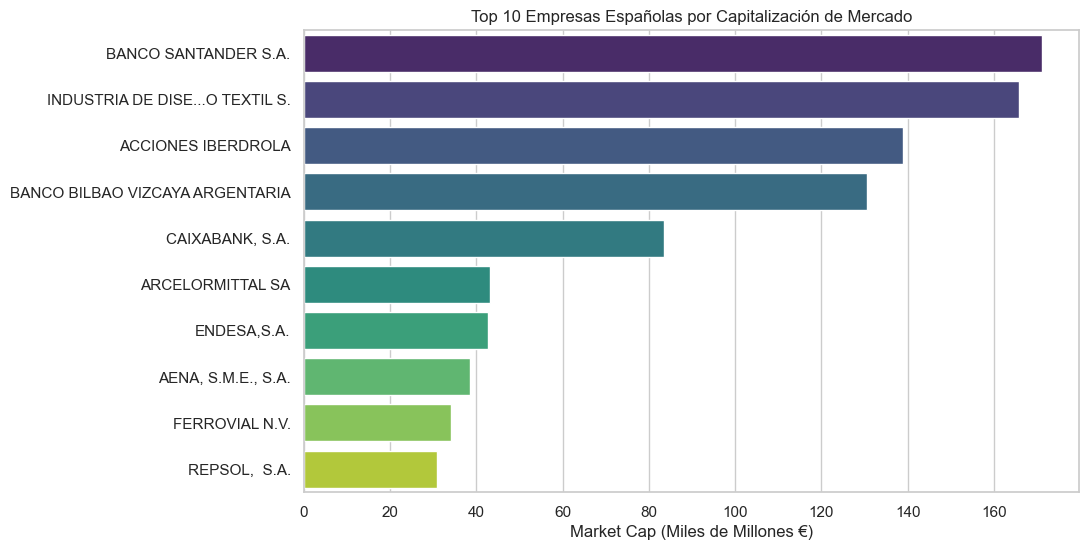

In [75]:
# 1.1 Top 10 Empresas por Capitalización
plt.figure(figsize=(10, 6))
top_10 = df_market.nlargest(10, 'MarketCap_B')
sns.barplot(data=top_10, x='MarketCap_B', y='Name', palette='viridis')
plt.title("Top 10 Empresas Españolas por Capitalización de Mercado")
plt.xlabel("Market Cap (Miles de Millones €)")
plt.ylabel("")
plt.show()

C:\Users\anxom\AppData\Local\Temp\ipykernel_2296\1544762923.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sector_mc, x='MarketCap_B', y='Sector', palette='rocket')


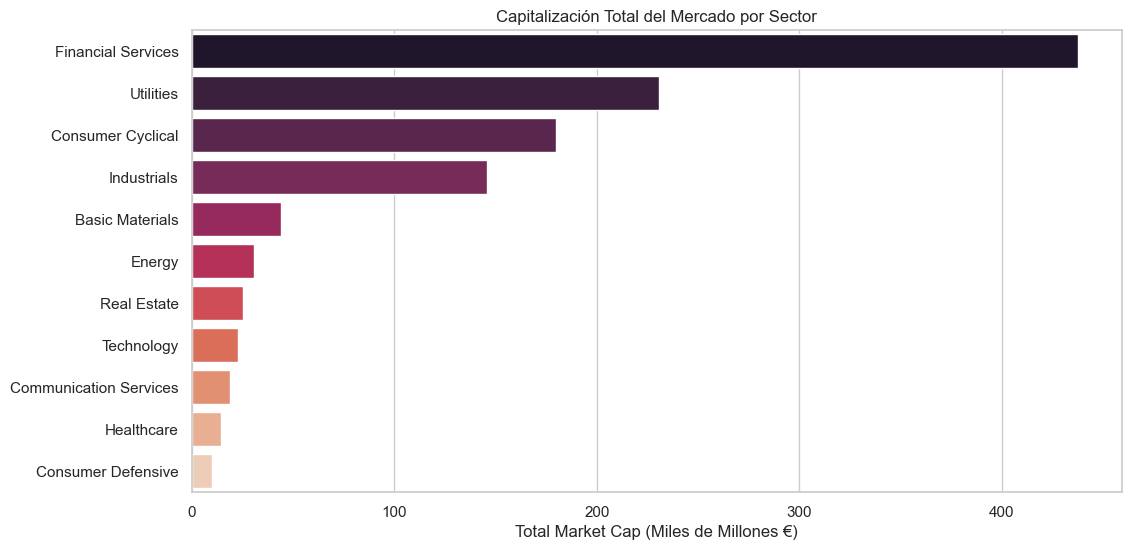

In [76]:
# 1.2 Dominio Sectorial (Oligopolio)
sector_mc = df_market.groupby('Sector')['MarketCap_B'].sum().sort_values(ascending=False).reset_index()

plt.figure(figsize=(12, 6))
sns.barplot(data=sector_mc, x='MarketCap_B', y='Sector', palette='rocket')
plt.title("Capitalización Total del Mercado por Sector")
plt.xlabel("Total Market Cap (Miles de Millones €)")
plt.ylabel("")
plt.show()

## 1.1 Conclusiones
El mercado español está fuertemente dominado por los servicios financieros (bancos) y las utilities (eléctricas), con un jugador aislado en el sector de consumo cíclico (Inditex). Esto sugiere un mercado estructuralmente concentrado, lo que puede tener implicaciones para la diversificación y la gestión de riesgos.

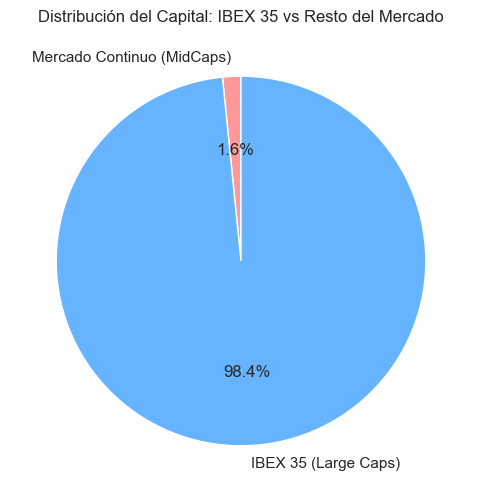

In [77]:
# 1.3 IBEX 35 vs MidCaps (Concentración del Índice)
index_mc = df_market.groupby('Is_IBEX35')['MarketCap_B'].sum().reset_index()
index_mc['Index'] = index_mc['Is_IBEX35'].map({True: 'IBEX 35 (Large Caps)', False: 'Mercado Continuo (MidCaps)'})

plt.figure(figsize=(6, 6))
plt.pie(index_mc['MarketCap_B'], labels=index_mc['Index'], autopct='%1.1f%%', startangle=90, colors=['#ff9999','#66b3ff'])
plt.title("Distribución del Capital: IBEX 35 vs Resto del Mercado")
plt.show()

# MODULE 2: LIQUIDITY ANALYSIS
The objetive is to analyze where liquidity flows

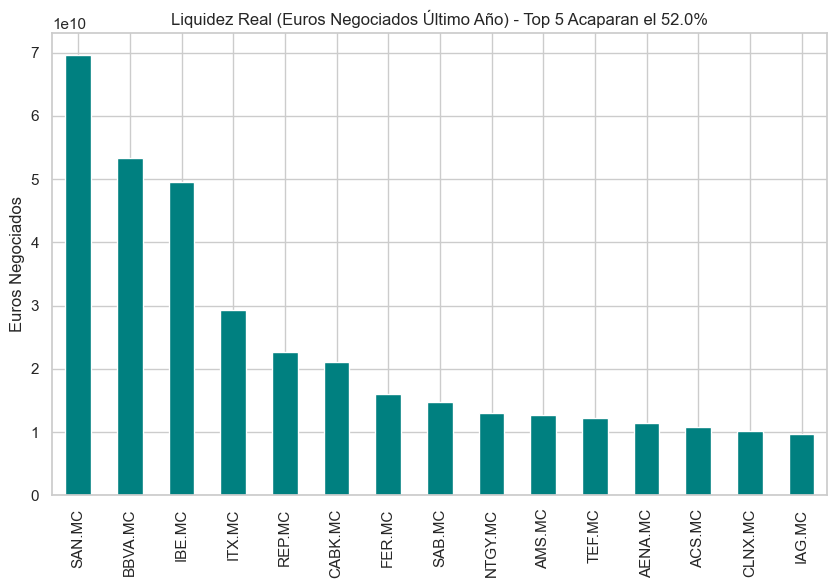

In [78]:
# 2.1 El Agujero Negro de Liquidez (Principio de Pareto)
# Calculamos el volumen total negociado en euros durante el último año
vol_euro_1y = (prices.tail(252) * volumes.tail(252)).sum()
vol_euro_1y = vol_euro_1y.sort_values(ascending=False)

top5_vol_pct = vol_euro_1y.head(5).sum() / vol_euro_1y.sum() * 100

plt.figure(figsize=(10, 6))
vol_euro_1y.head(15).plot(kind='bar', color='teal')
plt.title(f"Liquidez Real (Euros Negociados Último Año) - Top 5 Acaparan el {top5_vol_pct:.1f}%")
plt.ylabel("Euros Negociados")
plt.show()

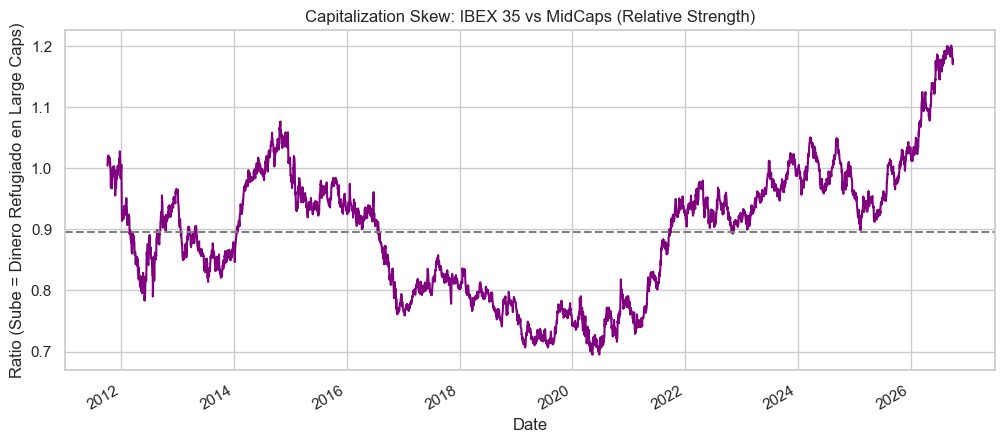

In [79]:
# 2.2 Capitalization Skew (Fuerza Relativa Large vs Mid)
ibex_ret = returns[ibex35_tickers].mean(axis=1)
midcap_ret = returns[midcap_tickers].mean(axis=1)

rs_ratio = (1 + ibex_ret).cumprod() / (1 + midcap_ret).cumprod()

plt.figure(figsize=(12, 5))
rs_ratio.plot(color='purple')
plt.title("Capitalization Skew: IBEX 35 vs MidCaps (Relative Strength)")
plt.ylabel("Ratio (Sube = Dinero Refugiado en Large Caps)")
plt.axhline(rs_ratio.mean(), color='gray', linestyle='--')
plt.show()

## 2.1 Conclusions
Most of the liquidity in the Spanish market is concentrated in a few large-cap stocks, particularly in the financial and utilities sectors. Mid-cap stocks, while numerous, suffer from low liquidity, making them less attractive for high-volume trading strategies. Investors should be cautious when considering mid-cap investments due to potential slippage and limited market depth. In addition, the current trend displays a greater flux from mid-cap to large-cap stocks, indicating a preference for stability and lower risk in the market.

# MODULE 3: MACRO AND EXTERNAL EXPOSURE
The goal of this module is to determine if an asset moves due to technical inertia (its own fundamentals and order flow) or if it acts as a "covert derivative" of a macroeconomic variable (currencies, commodities, or interest rates). This will help us apply directional filters to our trading signals.

We will divide this analysis into three distinct blocks:
1. **FX Analysis**: Impact of emerging market and global currencies (MXN, BRL, USD) on major banks (SAN, BBVA, CABK).
2. **Commodities Analysis**: Impact of Oil (Brent) on Utilities and Energy companies (REP, IBE, ELE).
3. **Bond Analysis**: Sensitivity of the market to Sovereign Debt Yields (Spanish and US Bonds).

In [80]:
# PREPARATION: Align and Clean Time Series
# We assume macro data is already loaded. Let's extract the relevant drivers.

# 1. Currencies (Invert pairs to get local currency strength against EUR)
macro_aligned = macro.copy()
if 'EURBRL' in macro_aligned.columns: macro_aligned['Strength_BRL'] = 1 / macro_aligned['EURBRL']
if 'EURMXN' in macro_aligned.columns: macro_aligned['Strength_MXN'] = 1 / macro_aligned['EURMXN']
if 'EURUSD' in macro_aligned.columns: macro_aligned['Strength_USD'] = 1 / macro_aligned['EURUSD']

# 2. Commodities
if 'BRENT_OIL' in macro_aligned.columns: macro_aligned['Oil'] = macro_aligned['BRENT_OIL']

# 3. Bonds
# Note: Yahoo Finance often lacks direct access to the Spanish 10Y Bond yield (ES10Y).
# If missing, we use the US10Y as a proxy for global yield trends.
macro_aligned['US_10Y_Bond'] = macro_aligned.get('US10Y', None)
# Fallback to US10Y if ES10Y is completely missing or NaN
if 'ES10Y' not in macro_aligned.columns or macro_aligned['ES10Y'].isnull().all():
    macro_aligned['ES_10Y_Bond'] = macro_aligned.get('US10Y', None)
else:
    macro_aligned['ES_10Y_Bond'] = macro_aligned['ES10Y'] # Fallback to US10Y if ES10Y is missing

# Keep only the features we need
macro_features = ['Strength_BRL', 'Strength_MXN', 'Strength_USD', 'Oil', 'US_10Y_Bond', 'ES_10Y_Bond']
macro_features = [f for f in macro_features if f in macro_aligned.columns]

# Reindex to the stock market calendar (returns.index), Forward Fill missing days
macro_aligned = macro_aligned[macro_features].reindex(returns.index).ffill()

# Convert to daily percentage returns
macro_returns = macro_aligned.pct_change().dropna(how='all')


## 3.1 FX Analysis (Currency Exposure)
Let's analyze how the major Spanish banks (Santander, BBVA, CaixaBank) react to fluctuations in the Mexican Peso (MXN), Brazilian Real (BRL), and the US Dollar (USD).

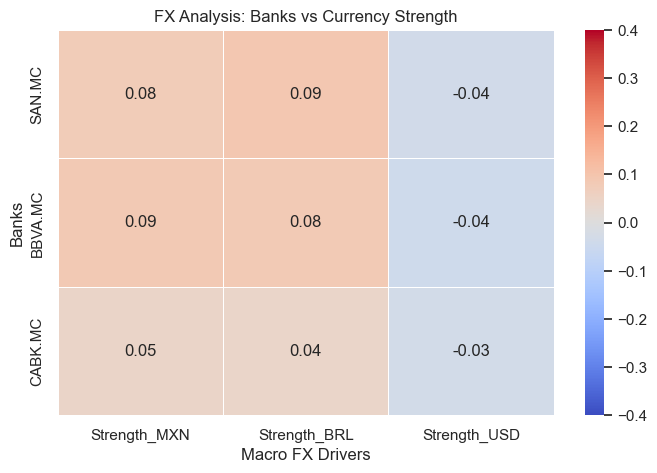

Interpretation:
- BBVA should show a strong positive correlation with MXN Strength.
- SAN should show a correlation with BRL Strength.
- CABK, being primarily a domestic bank, should remain relatively isolated (close to 0.0) from LATAM FX.


In [81]:
fx_banks = ['SAN.MC', 'BBVA.MC', 'CABK.MC']
fx_factors = [f for f in ['Strength_MXN', 'Strength_BRL', 'Strength_USD'] if f in macro_returns.columns]

# Merge and calculate correlation
merged_fx = pd.concat([returns[fx_banks], macro_returns[fx_factors]], axis=1).dropna()
corr_fx = merged_fx.corr().loc[fx_banks, fx_factors]

plt.figure(figsize=(8, 5))
sns.heatmap(corr_fx, annot=True, cmap='coolwarm', center=0, vmin=-0.4, vmax=0.4, fmt='.2f', linewidths=0.5)
plt.title("FX Analysis: Banks vs Currency Strength")
plt.ylabel("Banks")
plt.xlabel("Macro FX Drivers")
plt.show()

print("Interpretation:")
print("- BBVA should show a strong positive correlation with MXN Strength.")
print("- SAN should show a correlation with BRL Strength.")
print("- CABK, being primarily a domestic bank, should remain relatively isolated (close to 0.0) from LATAM FX.")

## 3.2 Commodities Analysis (Utilities & Energy)
Let's analyze how energy companies (Repsol) and utilities (Iberdrola, Endesa) react to Oil price fluctuations.

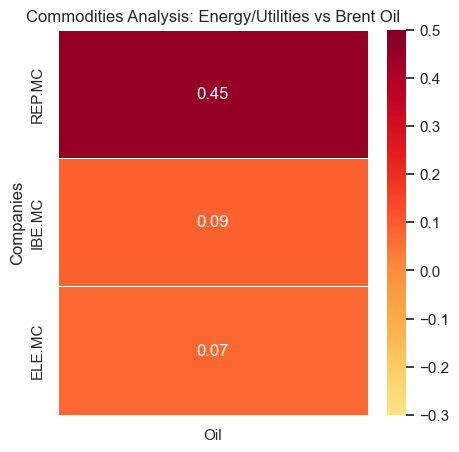

Interpretation:
- Repsol (REP.MC) operates in Oil & Gas and should have a strong positive correlation with Oil.
- Utilities (IBE.MC, ELE.MC) might show weak or negative correlation, as higher energy commodity prices can increase their input costs or be passed to consumers.


In [82]:
energy_utils = ['REP.MC', 'IBE.MC', 'ELE.MC']
commodities = ['Oil']

if 'Oil' in macro_returns.columns:
    merged_comm = pd.concat([returns[[t for t in energy_utils if t in returns.columns]], macro_returns[commodities]], axis=1).dropna()
    corr_comm = merged_comm.corr().loc[[t for t in energy_utils if t in returns.columns], commodities]

    plt.figure(figsize=(5, 5))
    sns.heatmap(corr_comm, annot=True, cmap='YlOrRd', center=0, vmin=-0.3, vmax=0.5, fmt='.2f', linewidths=0.5)
    plt.title("Commodities Analysis: Energy/Utilities vs Brent Oil")
    plt.ylabel("Companies")
    plt.show()
    
    print("Interpretation:")
    print("- Repsol (REP.MC) operates in Oil & Gas and should have a strong positive correlation with Oil.")
    print("- Utilities (IBE.MC, ELE.MC) might show weak or negative correlation, as higher energy commodity prices can increase their input costs or be passed to consumers.")

## 3.3 Bond Analysis (Interest Rate Sensitivity)
Let's analyze the sensitivity of the overall market and specific sectors against the US 10-Year Treasury Yield and the Spanish 10-Year Bond Yield.

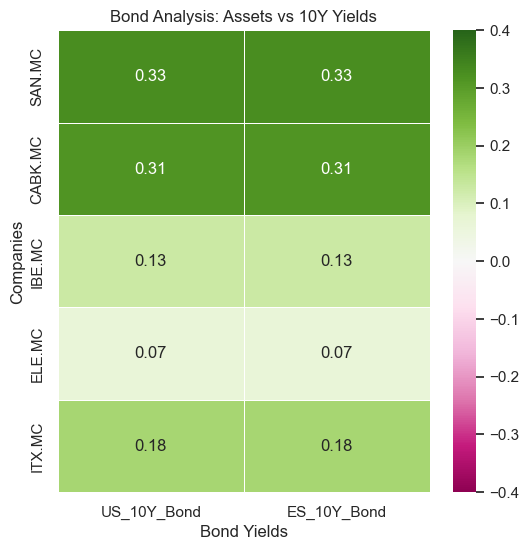

Interpretation:
- Banks (SAN, CABK) usually show positive correlation with Yields (higher rates = higher interest margins).
- Utilities (IBE, ELE) usually show negative correlation with Yields (higher rates = expensive debt financing for infrastructure).
- Note: If ES_10Y_Bond is identical to US_10Y_Bond, it means Yahoo Finance lacked the Spanish bond data and we used the US bond as a global proxy.


In [83]:
bond_factors = [f for f in ['US_10Y_Bond', 'ES_10Y_Bond'] if f in macro_returns.columns]
bond_assets = ['SAN.MC', 'CABK.MC', 'IBE.MC', 'ELE.MC', 'ITX.MC'] # Mix of Banks, Utilities, and Retail

merged_bonds = pd.concat([returns[[t for t in bond_assets if t in returns.columns]], macro_returns[bond_factors]], axis=1).dropna()
corr_bonds = merged_bonds.corr().loc[[t for t in bond_assets if t in returns.columns], bond_factors]

plt.figure(figsize=(6, 6))
sns.heatmap(corr_bonds, annot=True, cmap='PiYG', center=0, vmin=-0.4, vmax=0.4, fmt='.2f', linewidths=0.5)
plt.title("Bond Analysis: Assets vs 10Y Yields")
plt.ylabel("Companies")
plt.xlabel("Bond Yields")
plt.show()

print("Interpretation:")
print("- Banks (SAN, CABK) usually show positive correlation with Yields (higher rates = higher interest margins).")
print("- Utilities (IBE, ELE) usually show negative correlation with Yields (higher rates = expensive debt financing for infrastructure).")
print("- Note: If ES_10Y_Bond is identical to US_10Y_Bond, it means Yahoo Finance lacked the Spanish bond data and we used the US bond as a global proxy.")

# MÓDULO 4: COMPORTAMIENTO ESTRUCTURAL
## 4.1 La Ilusión del IBEX (Price Return vs Total Return)
A diferencia de EE.UU., las empresas españolas retribuyen vía dividendos, no vía recompras. Esto "drena" el índice visualmente en cada Ex-Date.

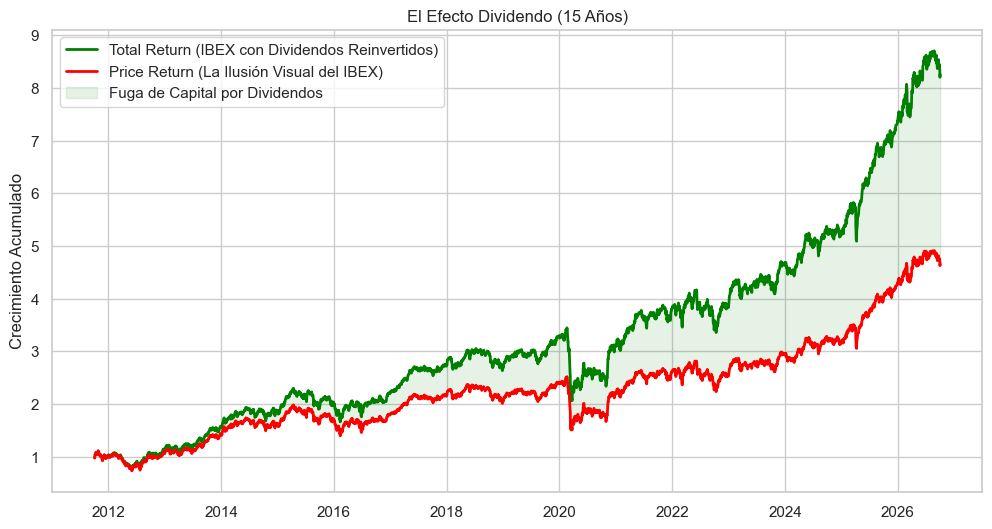

⚠️ RIESGO DEL CONCURSO: Si el motor del concurso de BME no abona efectivo en el Ex-Date, mantener acciones pagadoras de altos dividendos resultará en caídas de precio 'virtuales' que destruirán tu Sharpe Ratio. Debes programar tu bot para salir de la acción el día antes del dividendo.


In [84]:
ibex_price_ret = (1 + returns[ibex35_tickers].mean(axis=1)).cumprod()
ibex_total_ret = (1 + adj_returns[ibex35_tickers].mean(axis=1)).cumprod()

plt.figure(figsize=(12, 6))
plt.plot(ibex_total_ret.index, ibex_total_ret, label="Total Return (IBEX con Dividendos Reinvertidos)", color='green', linewidth=2)
plt.plot(ibex_price_ret.index, ibex_price_ret, label="Price Return (La Ilusión Visual del IBEX)", color='red', linewidth=2)

plt.fill_between(ibex_price_ret.index, ibex_price_ret, ibex_total_ret, color='green', alpha=0.1, label='Fuga de Capital por Dividendos')
plt.title("El Efecto Dividendo (15 Años)")
plt.ylabel("Crecimiento Acumulado")
plt.legend()
plt.show()

print("⚠️ RIESGO DEL CONCURSO: Si el motor del concurso de BME no abona efectivo en el Ex-Date, mantener acciones pagadoras de altos dividendos resultará en caídas de precio 'virtuales' que destruirán tu Sharpe Ratio. Debes programar tu bot para salir de la acción el día antes del dividendo.")

## 4.2 Asimetría de Beta (Up-Market vs Down-Market)
¿Cómo reacciona España cuando Europa entra en pánico? Evaluamos la Beta frente al `EUROSTOXX`.

In [85]:
if 'EUROSTOXX' in macro.columns and 'IBEX' in macro.columns:
    eu_ret = macro['EUROSTOXX'].pct_change().dropna()
    sp_ret = macro['IBEX'].pct_change().dropna()
    
    df_beta = pd.DataFrame({'EU': eu_ret, 'SP': sp_ret}).dropna()
    
    up_days = df_beta[df_beta['EU'] > 0]
    down_days = df_beta[df_beta['EU'] < 0]
    
    beta_up = np.cov(up_days['EU'], up_days['SP'])[0][1] / np.var(up_days['EU'])
    beta_down = np.cov(down_days['EU'], down_days['SP'])[0][1] / np.var(down_days['EU'])
    
    print(f"UP-MARKET BETA (Cuando Europa Sube): {beta_up:.2f}")
    print(f"DOWN-MARKET BETA (Cuando Europa Baja): {beta_down:.2f}\n")
    
    if beta_down > beta_up:
        print("MERCADO PERIFÉRICO: El IBEX sufre de Beta asimétrica. Cae más rápido en crisis de lo que sube en expansiones frente a sus pares europeos.")
    else:
        print("MERCADO DEFENSIVO: El peso de las Utilities protege al IBEX de las caídas drásticas de Europa.")

UP-MARKET BETA (Cuando Europa Sube): 0.88
DOWN-MARKET BETA (Cuando Europa Baja): 0.96

MERCADO PERIFÉRICO: El IBEX sufre de Beta asimétrica. Cae más rápido en crisis de lo que sube en expansiones frente a sus pares europeos.


C:\Users\anxom\AppData\Local\Temp\ipykernel_2296\2838376272.py:2: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  eu_ret = macro['EUROSTOXX'].pct_change().dropna()
C:\Users\anxom\AppData\Local\Temp\ipykernel_2296\2838376272.py:3: FutureWarning: The default fill_method='pad' in Series.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  sp_ret = macro['IBEX'].pct_change().dropna()


# MÓDULO 5: SALUD INTERNA (Amplitud)
¿Está el mercado subiendo apoyado por todos, o solo tiran del carro Inditex y Santander?

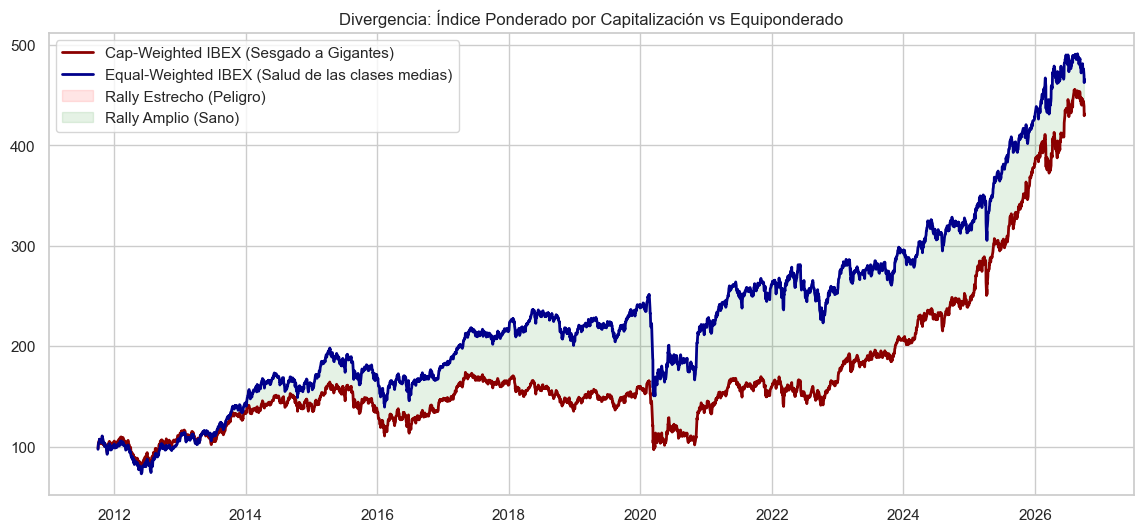

In [86]:
# 5.1 Cap-Weighted vs Equal-Weighted
# Recuperamos los Market Caps descargados
cap_tickers = [t for t in ibex35_tickers if t in df_market['Ticker'].values]
if len(cap_tickers) > 0:
    mcaps = df_market.set_index('Ticker').loc[cap_tickers, 'MarketCap_B']
    weights = mcaps / mcaps.sum()
    
    cap_weighted_ret = (returns[cap_tickers] * weights).sum(axis=1).fillna(0)
    cw_cum = (1 + cap_weighted_ret).cumprod() * 100
    
    equal_weighted_ret = returns[cap_tickers].mean(axis=1).fillna(0)
    ew_cum = (1 + equal_weighted_ret).cumprod() * 100
    
    plt.figure(figsize=(14, 6))
    plt.plot(cw_cum.index, cw_cum, label="Cap-Weighted IBEX (Sesgado a Gigantes)", color='darkred', linewidth=2)
    plt.plot(ew_cum.index, ew_cum, label="Equal-Weighted IBEX (Salud de las clases medias)", color='darkblue', linewidth=2)
    
    plt.fill_between(cw_cum.index, cw_cum, ew_cum, where=(cw_cum >= ew_cum), color='red', alpha=0.1, label='Rally Estrecho (Peligro)')
    plt.fill_between(cw_cum.index, cw_cum, ew_cum, where=(cw_cum < ew_cum), color='green', alpha=0.1, label='Rally Amplio (Sano)')
    
    plt.title("Divergencia: Índice Ponderado por Capitalización vs Equiponderado")
    plt.legend()
    plt.show()

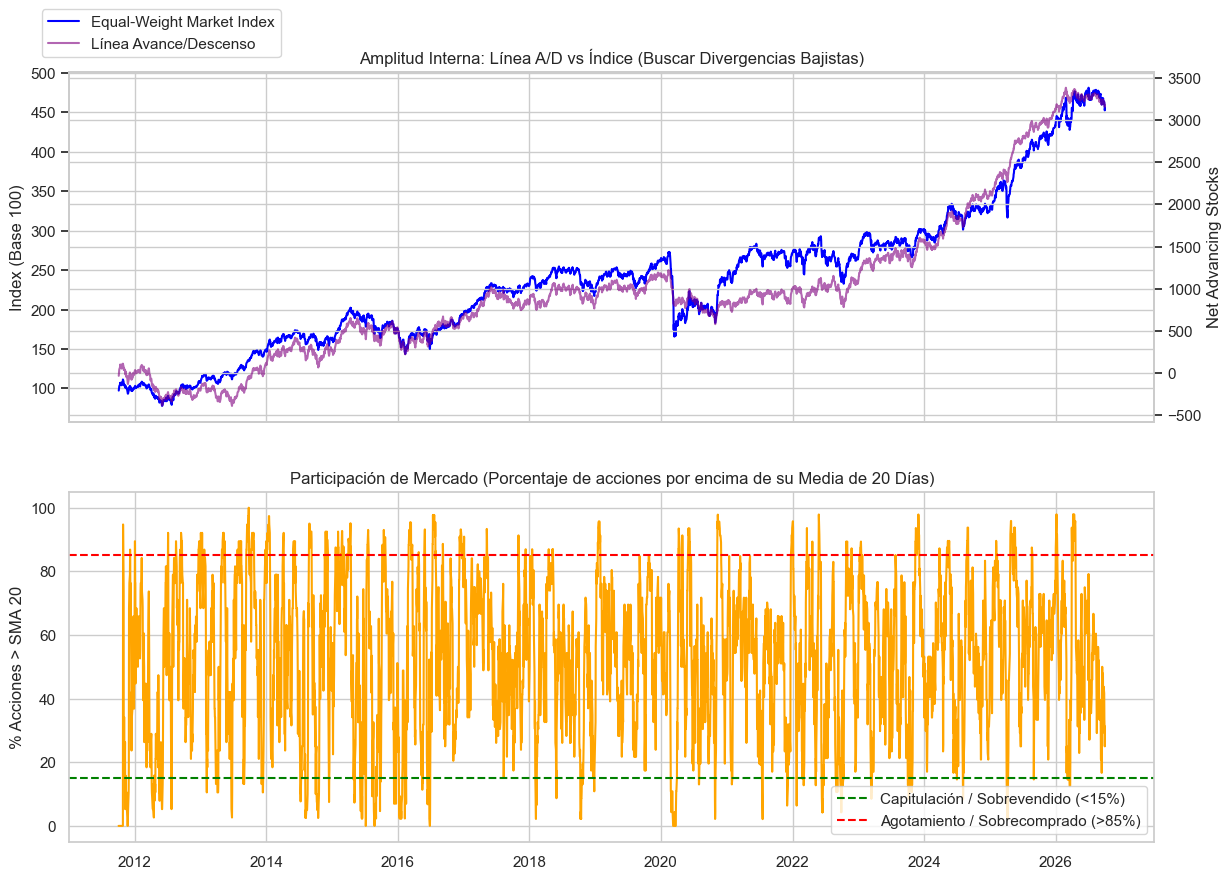

In [87]:
# 5.2 Market Breadth (A/D Line y SMA 20)
advancing = (returns > 0).sum(axis=1)
declining = (returns < 0).sum(axis=1)
ad_line = (advancing - declining).cumsum()

sma_20 = prices.rolling(20).mean()
above_sma = (prices > sma_20).sum(axis=1)
active_stocks = prices.notna().sum(axis=1)
pct_above_sma = (above_sma / active_stocks) * 100

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

# Advance/Decline
ew_index = (1 + returns.mean(axis=1)).cumprod() * 100
ax1.plot(ew_index.index, ew_index, label="Equal-Weight Market Index", color='blue')
ax1.set_ylabel("Index (Base 100)")
ax1_tw = ax1.twinx()
ax1_tw.plot(ad_line.index, ad_line, label="Línea Avance/Descenso", color='purple', alpha=0.6)
ax1_tw.set_ylabel("Net Advancing Stocks")
ax1.set_title("Amplitud Interna: Línea A/D vs Índice (Buscar Divergencias Bajistas)")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.95))

# SMA 20
ax2.plot(pct_above_sma.index, pct_above_sma, color='orange')
ax2.axhline(15, color='green', linestyle='--', label="Capitulación / Sobrevendido (<15%)")
ax2.axhline(85, color='red', linestyle='--', label="Agotamiento / Sobrecomprado (>85%)")
ax2.set_ylabel("% Acciones > SMA 20")
ax2.set_title("Participación de Mercado (Porcentaje de acciones por encima de su Media de 20 Días)")
ax2.legend()
plt.show()